In [1]:
from pathlib import Path
import pandas as pd

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

path = root / "data" / "processed" / "balanced_1000_1000_000_003.csv"
raw = pd.read_csv(path)

cols = {c.lower(): c for c in raw.columns}
def pick(*names):
    for n in names:
        if n.lower() in cols:
            return cols[n.lower()]
    return None

col_sha = pick("sha256", "phreshphish_sha256")
col_url = pick("url")
col_html = pick("html", "page_html", "raw_html", "html_content", "content")
col_label = pick("label")

use_cols = [c for c in [col_sha, col_url, col_html, col_label] if c is not None]
df_html = raw[use_cols].copy()

if col_sha is not None and col_sha != "sha256":
    df_html.rename(columns={col_sha: "sha256"}, inplace=True)
if col_url is not None and col_url != "url":
    df_html.rename(columns={col_url: "url"}, inplace=True)
if col_html is not None and col_html != "html":
    df_html.rename(columns={col_html: "html"}, inplace=True)
if col_label is not None and col_label != "label":
    df_html.rename(columns={col_label: "label"}, inplace=True)

s = df_html["label"].astype(str).str.lower().str.strip()
df_html["y"] = s.map({"benign": 0, "phish": 1})

df_html = df_html.dropna(subset=["url", "html", "y"]).copy()
df_html["y"] = df_html["y"].astype(int)

df_html.shape, df_html["y"].value_counts()

((2000, 5),
 y
 0    1000
 1    1000
 Name: count, dtype: int64)

In [2]:
try:
    from bs4 import BeautifulSoup
    from bs4.element import Tag, Comment
except ImportError:
    !pip -q install beautifulsoup4 lxml
    from bs4 import BeautifulSoup
    from bs4.element import Tag, Comment

import re
import numpy as np
from urllib.parse import urlparse

_susp_words = ["login","signin","verify","update","secure","account","password","bank","confirm","paypal","billing","support"]
_scheme_re = re.compile(r"^[a-zA-Z][a-zA-Z0-9+.-]*:")

def _host_norm(u):
    try:
        h = (urlparse(u).hostname or "").lower()
    except Exception:
        h = ""
    if h.startswith("www."):
        h = h[4:]
    return h

def _max_depth(soup):
    max_d = 0
    stack = [(soup, 0)]
    while stack:
        node, d = stack.pop()
        if isinstance(node, Tag):
            if d > max_d:
                max_d = d
            for ch in node.children:
                if isinstance(ch, Tag):
                    stack.append((ch, d + 1))
    return max_d

def html_features(url, html):
    h_raw = "" if html is None else str(html)
    h_lower = h_raw.lower()

    try:
        soup = BeautifulSoup(h_raw, "lxml")
    except Exception:
        soup = BeautifulSoup(h_raw, "html.parser")

    tags = soup.find_all(True)
    tag_names = [t.name for t in tags]
    tag_count = len(tags)
    unique_tag_count = len(set(tag_names))

    text = soup.get_text(" ", strip=True)
    text_len = len(text)

    forms = soup.find_all("form")
    inputs = soup.find_all("input")
    buttons = soup.find_all("button")
    iframes = soup.find_all("iframe")
    scripts = soup.find_all("script")
    images = soup.find_all("img")
    metas = soup.find_all("meta")

    input_types = [(i.get("type") or "text").lower().strip() for i in inputs]
    num_password = sum(t == "password" for t in input_types)
    num_hidden = sum(t == "hidden" for t in input_types)
    num_email = sum(t == "email" for t in input_types)
    num_submit = sum(t == "submit" for t in input_types)

    base_host = _host_norm(url)

    a_tags = soup.find_all("a", href=True)
    hrefs = [a.get("href", "").strip() for a in a_tags]

    num_links = len(hrefs)
    num_mailto = 0
    num_js_links = 0
    num_anchor = 0
    num_relative = 0
    num_internal = 0
    num_internal_sub = 0
    num_external = 0

    for href in hrefs:
        hl = href.lower()
        if hl == "":
            continue
        if hl.startswith("mailto:"):
            num_mailto += 1
            continue
        if hl.startswith("javascript:"):
            num_js_links += 1
            continue
        if hl.startswith("#"):
            num_anchor += 1
            continue

        if hl.startswith("//"):
            href2 = "http:" + href
        else:
            href2 = href

        if (not _scheme_re.match(href2)) and (href2.startswith("/") or not href2.startswith("//")):
            num_relative += 1
            continue

        try:
            h = _host_norm(href2)
        except Exception:
            h = ""

        if h == "":
            num_relative += 1
        else:
            if base_host != "" and h == base_host:
                num_internal += 1
            elif base_host != "" and h.endswith("." + base_host):
                num_internal_sub += 1
            else:
                num_external += 1

    script_src = [s.get("src", "").strip() for s in scripts if s.get("src")]
    num_script_src = len(script_src)
    num_external_script = 0
    for src in script_src:
        sl = src.lower()
        if sl.startswith("//"):
            src2 = "http:" + src
        else:
            src2 = src
        if _scheme_re.match(src2):
            h = _host_norm(src2)
            if base_host != "" and (h == base_host or h.endswith("." + base_host)):
                pass
            else:
                num_external_script += 1

    img_src = [i.get("src", "").strip() for i in images if i.get("src")]
    num_img_src = len(img_src)

    meta_refresh = 0
    for m in metas:
        heq = (m.get("http-equiv") or "").lower()
        if heq == "refresh":
            meta_refresh = 1
            break

    title_text = ""
    if soup.title and soup.title.string:
        title_text = str(soup.title.string).strip()

    num_comments = len(soup.find_all(string=lambda x: isinstance(x, Comment)))

    max_depth = _max_depth(soup)

    feats = {}
    feats["html_len"] = len(h_raw)
    feats["text_len"] = text_len
    feats["tag_count"] = tag_count
    feats["unique_tag_count"] = unique_tag_count
    feats["max_dom_depth"] = max_depth

    feats["num_forms"] = len(forms)
    feats["num_inputs"] = len(inputs)
    feats["num_buttons"] = len(buttons)
    feats["num_password_inputs"] = num_password
    feats["num_hidden_inputs"] = num_hidden
    feats["num_email_inputs"] = num_email
    feats["num_submit_inputs"] = num_submit
    feats["has_login_form"] = 1 if num_password > 0 else 0

    feats["num_iframes"] = len(iframes)
    feats["num_scripts"] = len(scripts)
    feats["num_script_src"] = num_script_src
    feats["num_external_scripts"] = num_external_script
    feats["num_images"] = len(images)
    feats["num_img_src"] = num_img_src
    feats["num_meta"] = len(metas)
    feats["has_meta_refresh"] = meta_refresh
    feats["num_comments"] = num_comments

    feats["title_len"] = len(title_text)
    feats["num_links"] = num_links
    feats["num_mailto_links"] = num_mailto
    feats["num_js_links"] = num_js_links
    feats["num_anchor_links"] = num_anchor
    feats["num_relative_links"] = num_relative
    feats["num_internal_links"] = num_internal
    feats["num_internal_subdomain_links"] = num_internal_sub
    feats["num_external_links"] = num_external
    feats["external_link_ratio"] = (num_external / num_links) if num_links > 0 else 0.0

    feats["suspicious_word_count"] = sum(1 for w in _susp_words if w in h_lower)

    return feats

html_features(df_html.iloc[0]["url"], df_html.iloc[0]["html"])

{'html_len': 53113,
 'text_len': 2858,
 'tag_count': 602,
 'unique_tag_count': 32,
 'max_dom_depth': 23,
 'num_forms': 0,
 'num_inputs': 3,
 'num_buttons': 5,
 'num_password_inputs': 0,
 'num_hidden_inputs': 0,
 'num_email_inputs': 0,
 'num_submit_inputs': 0,
 'has_login_form': 0,
 'num_iframes': 0,
 'num_scripts': 65,
 'num_script_src': 62,
 'num_external_scripts': 2,
 'num_images': 5,
 'num_img_src': 5,
 'num_meta': 1,
 'has_meta_refresh': 0,
 'num_comments': 2,
 'title_len': 10,
 'num_links': 79,
 'num_mailto_links': 0,
 'num_js_links': 1,
 'num_anchor_links': 68,
 'num_relative_links': 0,
 'num_internal_links': 0,
 'num_internal_subdomain_links': 4,
 'num_external_links': 6,
 'external_link_ratio': 0.0759493670886076,
 'suspicious_word_count': 2}

In [3]:
feat_h = pd.DataFrame.from_records(
    [html_features(u, h) for u, h in zip(df_html["url"].tolist(), df_html["html"].tolist())]
)

base_cols = ["sha256", "url", "label", "y"] if "sha256" in df_html.columns else ["url", "label", "y"]
features_html = pd.concat([df_html[base_cols].reset_index(drop=True), feat_h.reset_index(drop=True)], axis=1)

features_html.shape

(2000, 37)

In [4]:
from pathlib import Path

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

out_path = root / "data" / "processed" / "features_html_1000_1000_000_003.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)

features_html.to_csv(out_path, index=False)
str(out_path)

'c:\\Users\\14176\\Desktop\\Honours Project\\Hons Project\\data\\processed\\features_html_1000_1000_000_003.csv'

In [5]:
drop_cols = [c for c in ["sha256", "url", "label", "y"] if c in features_html.columns]
Xh = features_html.drop(columns=drop_cols)
yh = features_html["y"].astype(int)

from sklearn.model_selection import train_test_split
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    Xh, yh, test_size=0.2, random_state=42, stratify=yh
)

Xh_train.shape, Xh_test.shape

((1600, 33), (400, 33))

[[169  31]
 [ 17 183]]
              precision    recall  f1-score   support

           0     0.9086    0.8450    0.8756       200
           1     0.8551    0.9150    0.8841       200

    accuracy                         0.8800       400
   macro avg     0.8819    0.8800    0.8799       400
weighted avg     0.8819    0.8800    0.8799       400

0.9475


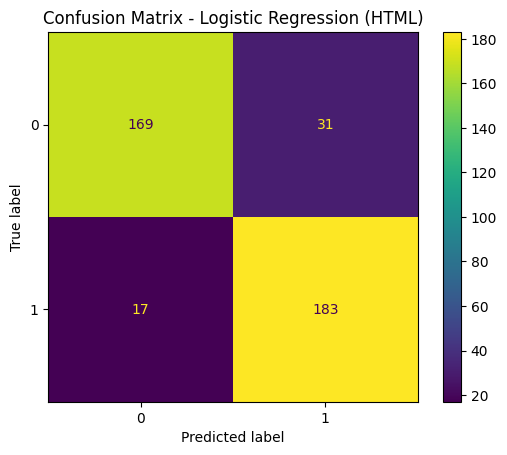

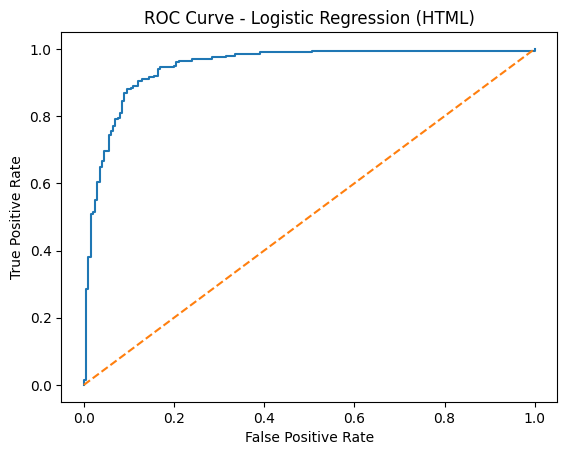

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

lr_h = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000))
])

lr_h.fit(Xh_train, yh_train)

yh_prob = lr_h.predict_proba(Xh_test)[:, 1]
yh_pred = (yh_prob >= 0.5).astype(int)

print(confusion_matrix(yh_test, yh_pred))
print(classification_report(yh_test, yh_pred, digits=4))
print(roc_auc_score(yh_test, yh_prob))

ConfusionMatrixDisplay.from_predictions(yh_test, yh_pred)
plt.title("Confusion Matrix - Logistic Regression (HTML)")
plt.show()

fpr, tpr, _ = roc_curve(yh_test, yh_prob)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression (HTML)")
plt.show()

[[189  11]
 [ 14 186]]
              precision    recall  f1-score   support

           0     0.9310    0.9450    0.9380       200
           1     0.9442    0.9300    0.9370       200

    accuracy                         0.9375       400
   macro avg     0.9376    0.9375    0.9375       400
weighted avg     0.9376    0.9375    0.9375       400

0.9886


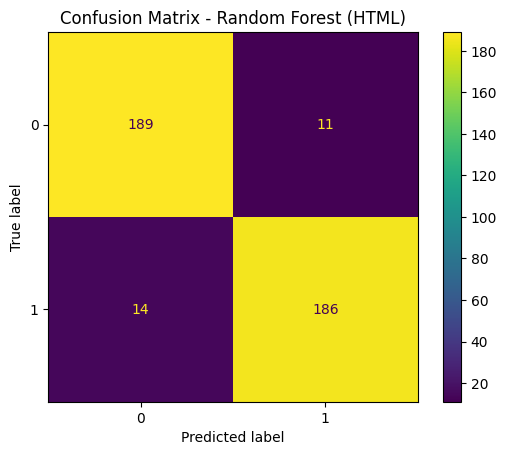

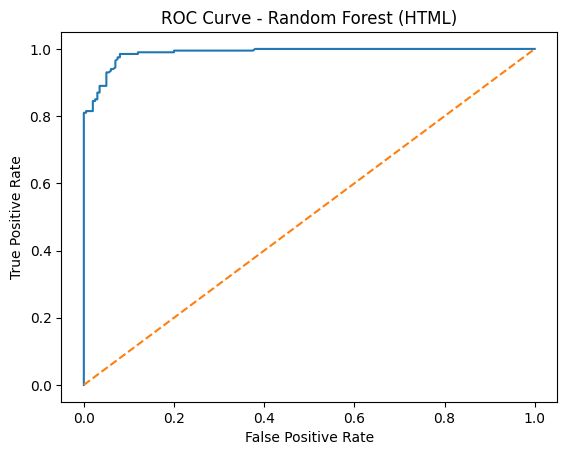

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf_h = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_h.fit(Xh_train, yh_train)

yh_prob = rf_h.predict_proba(Xh_test)[:, 1]
yh_pred = (yh_prob >= 0.5).astype(int)

print(confusion_matrix(yh_test, yh_pred))
print(classification_report(yh_test, yh_pred, digits=4))
print(roc_auc_score(yh_test, yh_prob))

ConfusionMatrixDisplay.from_predictions(yh_test, yh_pred)
plt.title("Confusion Matrix - Random Forest (HTML)")
plt.show()

fpr, tpr, _ = roc_curve(yh_test, yh_prob)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest (HTML)")
plt.show()

In [8]:
try:
    import xgboost as xgb
except ImportError:
    !pip -q install xgboost
    import xgboost as xgb

[[188  12]
 [ 10 190]]
              precision    recall  f1-score   support

           0     0.9495    0.9400    0.9447       200
           1     0.9406    0.9500    0.9453       200

    accuracy                         0.9450       400
   macro avg     0.9450    0.9450    0.9450       400
weighted avg     0.9450    0.9450    0.9450       400

0.9887250000000001


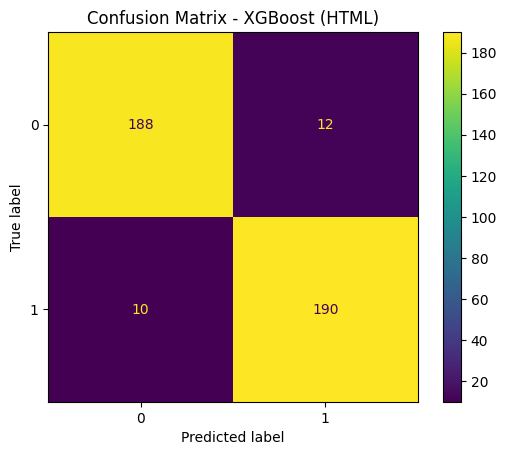

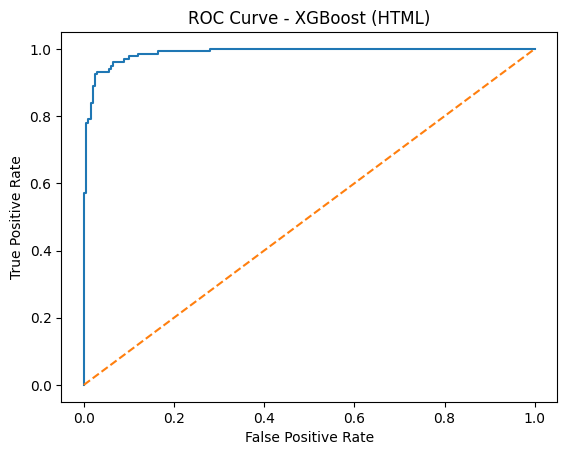

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

xgb_h = xgb.XGBClassifier(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    min_child_weight=1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_h.fit(Xh_train, yh_train)

yh_prob = xgb_h.predict_proba(Xh_test)[:, 1]
yh_pred = (yh_prob >= 0.5).astype(int)

print(confusion_matrix(yh_test, yh_pred))
print(classification_report(yh_test, yh_pred, digits=4))
print(roc_auc_score(yh_test, yh_prob))

ConfusionMatrixDisplay.from_predictions(yh_test, yh_pred)
plt.title("Confusion Matrix - XGBoost (HTML)")
plt.show()

fpr, tpr, _ = roc_curve(yh_test, yh_prob)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost (HTML)")
plt.show()

In [10]:
rows_h = []

for name, model in [("LogReg_HTML", lr_h), ("RF_HTML", rf_h), ("XGBoost_HTML", xgb_h)]:
    yh_prob = model.predict_proba(Xh_test)[:, 1]
    yh_pred = (yh_prob >= 0.5).astype(int)
    auc = roc_auc_score(yh_test, yh_prob)
    cm = confusion_matrix(yh_test, yh_pred)
    rows_h.append({
        "model": name,
        "roc_auc": float(auc),
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1])
    })

metrics_html_df = pd.DataFrame(rows_h).sort_values("roc_auc", ascending=False).reset_index(drop=True)
metrics_html_df

,model,roc_auc,tn,fp,fn,tp
0,XGBoost_HTML,0.988725,188,12,10,190
1,RF_HTML,0.988600,189,11,14,186
2,LogReg_HTML,0.947500,169,31,17,183


In [11]:
best_name_h = metrics_html_df.loc[0, "model"]
best_model_h = {"LogReg_HTML": lr_h, "RF_HTML": rf_h, "XGBoost_HTML": xgb_h}[best_name_h]

yh_prob = best_model_h.predict_proba(Xh_test)[:, 1]
yh_pred = (yh_prob >= 0.5).astype(int)

view_h = features_html.loc[Xh_test.index, ["url", "label", "y"]].copy()
view_h["pred"] = yh_pred
view_h["proba"] = yh_prob

fp_h = view_h[(view_h["y"] == 0) & (view_h["pred"] == 1)].sort_values("proba", ascending=False)
fn_h = view_h[(view_h["y"] == 1) & (view_h["pred"] == 0)].sort_values("proba", ascending=True)

best_name_h

'XGBoost_HTML'

In [12]:
from IPython.display import display

display(fp_h.head(20))
display(fn_h.head(20))

,url,label,y,pred,proba
931,https://gcps.powerschool.com/teachers/studentp...,benign,0,1,0.995821
581,https://studio.youtube.com/channel/uc2xucukpet...,benign,0,1,0.945067
1890,https://embeds.audioboom.com/posts/7920017/emb...,benign,0,1,0.933208
187,https://cochise.maps.arcgis.com/apps/webappvie...,benign,0,1,0.888269
498,https://www.woolworths.co.nz/shop/browse/pantr...,benign,0,1,0.787274
1433,https://www.allbirds.com/wpm@f69b9fb6w3396cff1...,benign,0,1,0.714795
1028,https://app.saluteelavoro.eu/sallav/ipdfviewer...,benign,0,1,0.692416
1641,https://www.hipaaspace.com/medical_billing/cod...,benign,0,1,0.651720
1255,https://www.coccinelle.com/,benign,0,1,0.626182
921,https://web.snelstart.nl/ef30ad51-7bf5-4f6f-ba...,benign,0,1,0.623369


,url,label,y,pred,proba
638,https://app-centralbankwebsite-prod-eus2.azure...,phish,1,0,0.015407
1233,http://bit.ly/404VKUa,phish,1,0,0.066396
266,https://glossvita.com/cart/checkout,phish,1,0,0.072195
430,https://ns2.caterpillarshoes.us.com,phish,1,0,0.147624
1903,https://premierpet-golden.shop/inicio/quiz/,phish,1,0,0.255502
1806,http://secure.malaycxmdirect.com,phish,1,0,0.262216
1287,http://oceandeepinternational.org/,phish,1,0,0.340658
1673,https://trezorstartfaq.groovehq.com/help/en-us,phish,1,0,0.340827
42,http://zh-cnp-williamhill.com/,phish,1,0,0.442623
628,https://l.ead.me/6dadaf94b61733a2d38775c78a99dc6a,phish,1,0,0.450264


In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"f1": "f1", "roc_auc": "roc_auc", "accuracy": "accuracy"}

models_h = {"LogReg_HTML": lr_h, "RF_HTML": rf_h, "XGBoost_HTML": xgb_h}

cv_rows_h = []
for name, m in models_h.items():
    out = cross_validate(m, Xh, yh, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows_h.append({
        "model": name,
        "f1_mean": float(np.mean(out["test_f1"])),
        "f1_std": float(np.std(out["test_f1"])),
        "auc_mean": float(np.mean(out["test_roc_auc"])),
        "auc_std": float(np.std(out["test_roc_auc"])),
        "acc_mean": float(np.mean(out["test_accuracy"])),
        "acc_std": float(np.std(out["test_accuracy"]))
    })

cv_html_df = pd.DataFrame(cv_rows_h).sort_values("auc_mean", ascending=False).reset_index(drop=True)
cv_html_df

,model,f1_mean,f1_std,auc_mean,auc_std,acc_mean,acc_std
0,XGBoost_HTML,0.926500,0.009361,0.97941,0.003309,0.9270,0.008860
1,RF_HTML,0.915315,0.006974,0.97707,0.003568,0.9165,0.006442
2,LogReg_HTML,0.857155,0.008956,0.92175,0.005569,0.8505,0.010173


In [14]:
import pandas as pd
import matplotlib.pyplot as plt

feat_names_h = Xh.columns.tolist()

rf_imp_h = pd.Series(rf_h.feature_importances_, index=feat_names_h).sort_values(ascending=False)
xgb_imp_h = pd.Series(xgb_h.feature_importances_, index=feat_names_h).sort_values(ascending=False)

top_n = 20
rf_top_h = rf_imp_h.head(top_n).reset_index()
rf_top_h.columns = ["feature", "importance"]

xgb_top_h = xgb_imp_h.head(top_n).reset_index()
xgb_top_h.columns = ["feature", "importance"]

rf_top_h

,feature,importance
0,num_external_links,0.101854
1,num_scripts,0.099165
2,num_script_src,0.075533
3,html_len,0.068770
4,tag_count,0.059893
5,unique_tag_count,0.056974
6,num_links,0.055987
7,text_len,0.046147
8,num_external_scripts,0.041737
9,external_link_ratio,0.038585


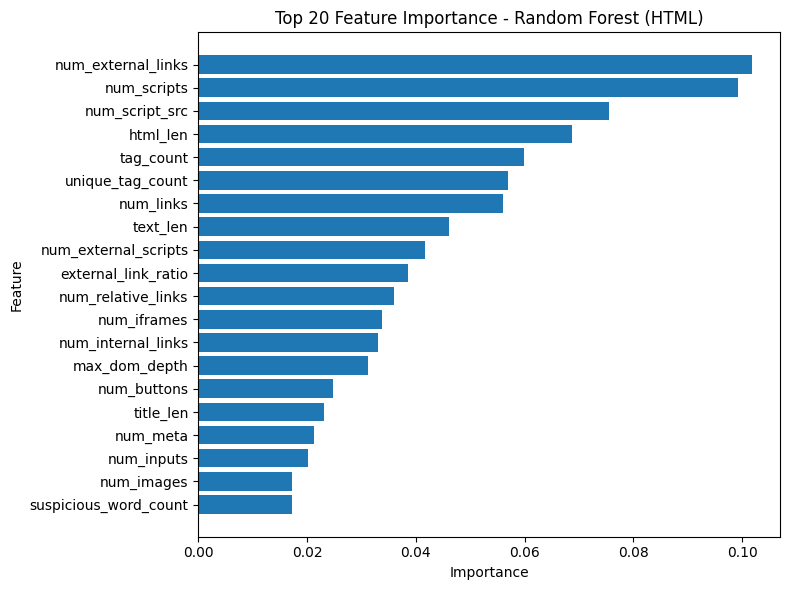

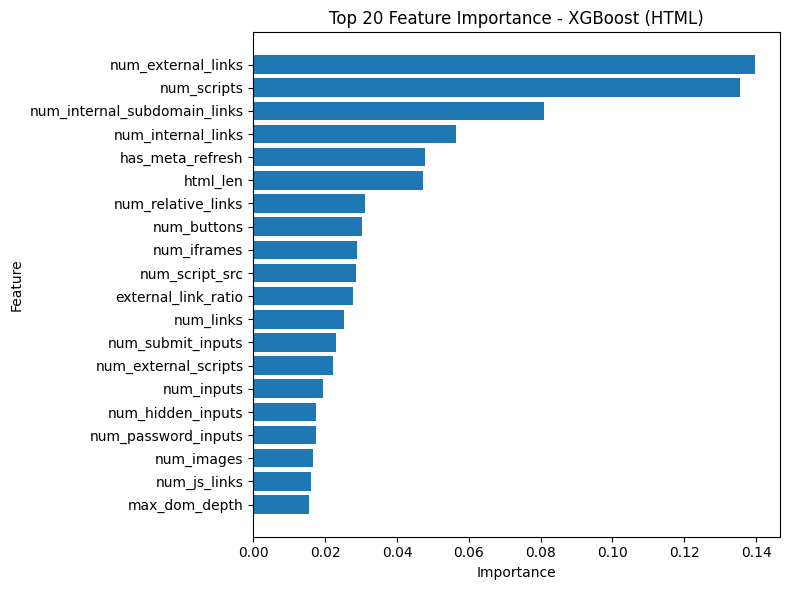

In [23]:
def plot_top_importance(df, title):
    plt.figure(figsize=(8, 6))
    plt.barh(df["feature"].iloc[::-1], df["importance"].iloc[::-1])
    plt.title(title)
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

plot_top_importance(rf_top_h, "Top 20 Feature Importance - Random Forest (HTML)")
plot_top_importance(xgb_top_h, "Top 20 Feature Importance - XGBoost (HTML)")

d:\anaconda\envs\py311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


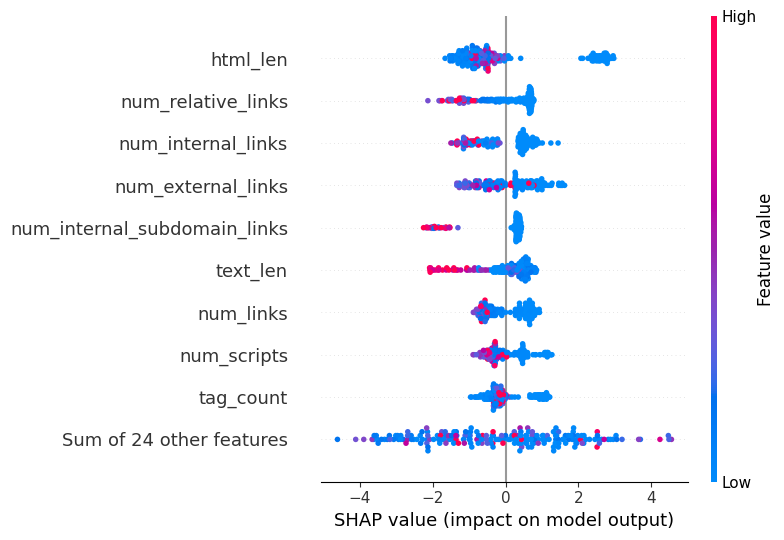

In [16]:
try:
    import shap
except ImportError:
    !pip -q install shap
    import shap

import matplotlib.pyplot as plt

Xh_sample = Xh_test.sample(n=min(200, len(Xh_test)), random_state=42)
explainer_h = shap.Explainer(xgb_h, Xh_sample)
sv_h = explainer_h(Xh_sample)

shap.plots.beeswarm(sv_h, show=False)
plt.tight_layout()
plt.show()

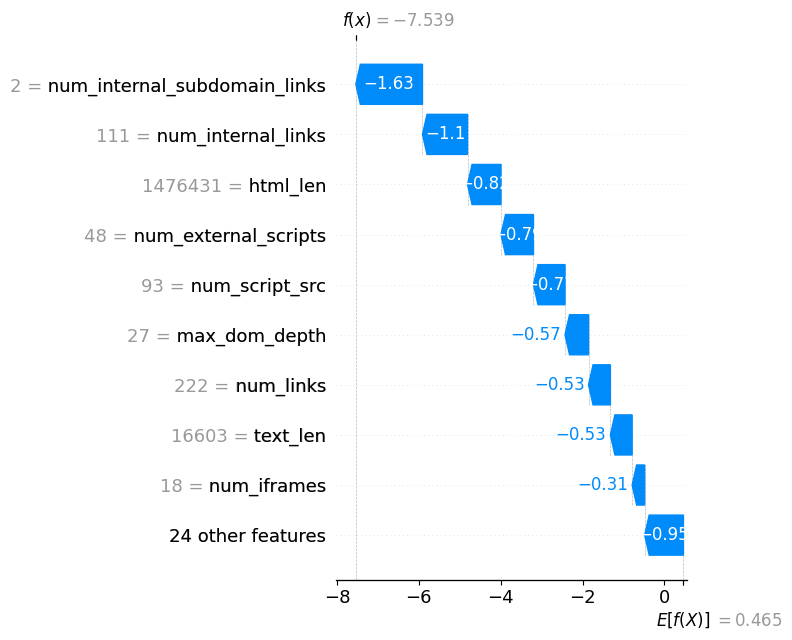

In [17]:
import matplotlib.pyplot as plt

idx = Xh_test.index[0]
x_one_h = Xh_test.loc[[idx]]
sv_one_h = explainer_h(x_one_h)

shap.plots.waterfall(sv_one_h[0], show=False)
plt.tight_layout()
plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt

X_tr, X_val, y_tr, y_val = train_test_split(
    Xh_train, yh_train, test_size=0.25, random_state=42, stratify=yh_train
)

if best_name_h == "LogReg_HTML":
    m1 = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000))])
    m2 = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000))])
elif best_name_h == "RF_HTML":
    m1 = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
    m2 = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
else:
    m1 = xgb.XGBClassifier(**xgb_h.get_params())
    m2 = xgb.XGBClassifier(**xgb_h.get_params())

m1.fit(X_tr, y_tr)
val_prob = m1.predict_proba(X_val)[:, 1]
p, r, th = precision_recall_curve(y_val, val_prob)

p2, r2 = p[1:], r[1:]
f1 = (2 * p2 * r2) / (p2 + r2 + 1e-12)
best_i = int(np.argmax(f1))
best_th_h = float(th[best_i])

m2.fit(Xh_train, yh_train)
test_prob_h = m2.predict_proba(Xh_test)[:, 1]
test_pred_h = (test_prob_h >= best_th_h).astype(int)

best_th_h, roc_auc_score(yh_test, test_prob_h), confusion_matrix(yh_test, test_pred_h)

(0.353875994682312,
 0.9887250000000001,
 array([[183,  17],
        [  8, 192]]))

              precision    recall  f1-score   support

           0     0.9581    0.9150    0.9361       200
           1     0.9187    0.9600    0.9389       200

    accuracy                         0.9375       400
   macro avg     0.9384    0.9375    0.9375       400
weighted avg     0.9384    0.9375    0.9375       400



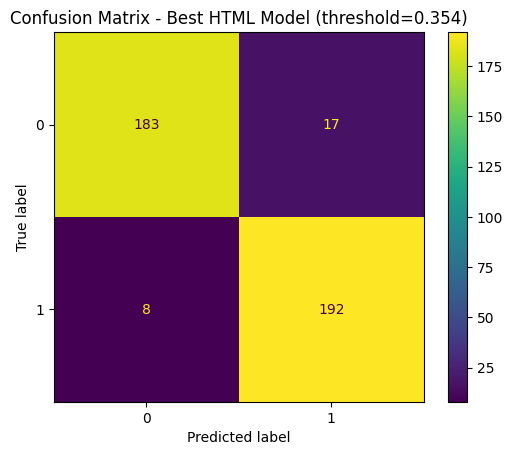

In [19]:
print(classification_report(yh_test, test_pred_h, digits=4))

ConfusionMatrixDisplay.from_predictions(yh_test, test_pred_h)
plt.title(f"Confusion Matrix - Best HTML Model (threshold={best_th_h:.3f})")
plt.show()

In [20]:
view_th_h = features_html.loc[Xh_test.index, ["url", "label", "y"]].copy()
view_th_h["pred"] = test_pred_h
view_th_h["proba"] = test_prob_h

fp_th_h = view_th_h[(view_th_h["y"] == 0) & (view_th_h["pred"] == 1)].sort_values("proba", ascending=False)
fn_th_h = view_th_h[(view_th_h["y"] == 1) & (view_th_h["pred"] == 0)].sort_values("proba", ascending=True)

from IPython.display import display
display(fp_th_h.head(20))
display(fn_th_h.head(20))

,url,label,y,pred,proba
931,https://gcps.powerschool.com/teachers/studentp...,benign,0,1,0.995821
581,https://studio.youtube.com/channel/uc2xucukpet...,benign,0,1,0.945067
1890,https://embeds.audioboom.com/posts/7920017/emb...,benign,0,1,0.933208
187,https://cochise.maps.arcgis.com/apps/webappvie...,benign,0,1,0.888269
498,https://www.woolworths.co.nz/shop/browse/pantr...,benign,0,1,0.787274
1433,https://www.allbirds.com/wpm@f69b9fb6w3396cff1...,benign,0,1,0.714795
1028,https://app.saluteelavoro.eu/sallav/ipdfviewer...,benign,0,1,0.692416
1641,https://www.hipaaspace.com/medical_billing/cod...,benign,0,1,0.651720
1255,https://www.coccinelle.com/,benign,0,1,0.626182
921,https://web.snelstart.nl/ef30ad51-7bf5-4f6f-ba...,benign,0,1,0.623369


,url,label,y,pred,proba
638,https://app-centralbankwebsite-prod-eus2.azure...,phish,1,0,0.015407
1233,http://bit.ly/404VKUa,phish,1,0,0.066396
266,https://glossvita.com/cart/checkout,phish,1,0,0.072195
430,https://ns2.caterpillarshoes.us.com,phish,1,0,0.147624
1903,https://premierpet-golden.shop/inicio/quiz/,phish,1,0,0.255502
1806,http://secure.malaycxmdirect.com,phish,1,0,0.262216
1287,http://oceandeepinternational.org/,phish,1,0,0.340658
1673,https://trezorstartfaq.groovehq.com/help/en-us,phish,1,0,0.340827


In [21]:
rf_th_row_h = {
    "model": "Best_HTML(threshold)",
    "roc_auc": float(roc_auc_score(yh_test, test_prob_h)),
    "tn": int(confusion_matrix(yh_test, test_pred_h)[0, 0]),
    "fp": int(confusion_matrix(yh_test, test_pred_h)[0, 1]),
    "fn": int(confusion_matrix(yh_test, test_pred_h)[1, 0]),
    "tp": int(confusion_matrix(yh_test, test_pred_h)[1, 1]),
    "threshold": float(best_th_h)
}

metrics_html_df2 = pd.concat([metrics_html_df, pd.DataFrame([rf_th_row_h])], ignore_index=True)
metrics_html_df2

,model,roc_auc,tn,fp,fn,tp,threshold
0,XGBoost_HTML,0.988725,188,12,10,190,NaN
1,RF_HTML,0.988600,189,11,14,186,NaN
2,LogReg_HTML,0.947500,169,31,17,183,NaN
3,Best_HTML(threshold),0.988725,183,17,8,192,0.353876


In [22]:
from pathlib import Path

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

report_dir = root / "data" / "processed" / "report_tables"
report_dir.mkdir(parents=True, exist_ok=True)

metrics_html_df2.to_csv(report_dir / "html_metrics_testset.csv", index=False)
cv_html_df.to_csv(report_dir / "html_metrics_cv5.csv", index=False)
rf_top_h.to_csv(report_dir / "html_rf_top20_features.csv", index=False)
xgb_top_h.to_csv(report_dir / "html_xgb_top20_features.csv", index=False)

fp_th_h.head(50).to_csv(report_dir / "html_fp_top50.csv", index=False)
fn_th_h.head(50).to_csv(report_dir / "html_fn_top50.csv", index=False)

str(report_dir)

'c:\\Users\\14176\\Desktop\\Honours Project\\Hons Project\\data\\processed\\report_tables'